# Kanz | كنز — EDA

Goal:
* Explore the data and find the numbers that support our story.

Our story = 5 questions (one per app tab):
```
1 Why care?                      -> the ocean is mostly unknown
2 Where is the treasure?         -> Discover
3 What threatens it?             -> Danger (heat -> bleaching, coral -> fish)
4 Where will we lose it first?   -> At Risk (today's heat + Red Sea)
5 What can we do?                -> Dive & Act (dive sites + rare species)
```

Who does what:
```
Member 1 -> Task 1, Task 2   (Discover)
Member 2 -> Task 3, Task 4   (Danger)
Member 3 -> Task 5, Task 6   (At Risk)
Member 4 -> Task 7           (Dive & Act)
Everyone -> Task 8           (summary)
```

Rules:
* Write the real numbers in every answer (they go to the slides and `docs/decisions.md`)
* Read `Kanz_Build_Plan.md` first → section 2 "Data traps" (important notes about the data)

In [1]:
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# works inside the project (notebooks/) and inside the shared zip folder
DATA = "../datasets_csv/" if os.path.exists("../datasets_csv") else "datasets_csv/"

# Load the data

All 10 files are loaded here, so the tasks can start directly.

In [2]:
# the 3 biggest files are compressed (.csv.gz) -> pandas reads them the same way

# coral bleaching: missing values are written as "nd"
bleaching = pd.read_csv(DATA + "coral_bleaching_surveys.csv.gz", na_values=["nd"], low_memory=False)

# NOAA reef heat stress
stations = pd.read_csv(DATA + "noaa_reef_stations.csv")
heat = pd.read_csv(DATA + "noaa_reef_heat_stress_daily.csv.gz")

# Reef Life Survey
surveys = pd.read_csv(DATA + "reef_life_surveys.csv")
sites = pd.read_csv(DATA + "reef_life_sites.csv")

# OBIS
animals = pd.read_csv(DATA + "obis_marine_animal_species.csv.gz", low_memory=False)
grid = pd.read_csv(DATA + "ocean_grid_cells.csv")
threatened = pd.read_csv(DATA + "threatened_species_near_dive_sites.csv")

# deep-sea corals + sea temperature trend
corals = pd.read_csv(DATA + "deep_sea_corals_species.csv")
sst_trend = pd.read_csv(DATA + "sea_temperature_anomaly.csv")

In [3]:
# quick overview of every table
tables = {"bleaching": bleaching, "stations": stations, "heat": heat, "surveys": surveys, "sites": sites,
          "animals": animals, "grid": grid, "threatened": threatened,
          "corals": corals, "sst_trend": sst_trend}

overview = pd.DataFrame({
    "rows": [len(df) for df in tables.values()],
    "columns": [df.shape[1] for df in tables.values()],
    "missing %": [round(df.isna().mean().mean() * 100, 1) for df in tables.values()],
}, index=tables.keys())

overview

,rows,columns,missing %
bleaching,41361,62,8.6
stations,214,4,0.0
heat,156220,11,0.0
surveys,36447,9,11.8
sites,4894,12,0.0
animals,164232,11,10.0
grid,1881,12,0.5
threatened,5019,5,0.0
corals,4384,8,8.2
sst_trend,531,6,0.0


In [4]:
bleaching.head()

,Site_ID,Sample_ID,Data_Source,Latitude_Degrees,Longitude_Degrees,Ocean_Name,Reef_ID,Realm_Name,Ecoregion_Name,Country_Name,...,TSA_FrequencyMax,TSA_FrequencyMean,TSA_DHW,TSA_DHW_Standard_Deviation,TSA_DHWMax,TSA_DHWMean,Date,Site_Comments,Sample_Comments,Bleaching_Comments
0,2501,10324336,Donner,23.163,-82.5260,Atlantic,NaN,Tropical Atlantic,Cuba and Cayman Islands,Cuba,...,5.0,0.0,0.00,0.74,7.25,0.18,2005-09-15,NaN,NaN,NaN
1,3467,10324754,Donner,-17.575,-149.7833,Pacific,NaN,Eastern Indo-Pacific,Society Islands French Polynesia,French Polynesia,...,4.0,0.0,0.26,0.67,4.65,0.19,1991-03-15,The bleaching does not appear to have gained ...,The bleaching does not appear to have gained ...,NaN
2,1794,10323866,Donner,18.369,-64.5640,Atlantic,NaN,Tropical Atlantic,Hispaniola Puerto Rico and Lesser Antilles,United Kingdom,...,7.0,0.0,0.00,1.04,11.66,0.26,2006-01-15,NaN,NaN,NaN
3,8647,10328028,Donner,17.760,-64.5680,Atlantic,NaN,Tropical Atlantic,Hispaniola Puerto Rico and Lesser Antilles,United States,...,4.0,0.0,0.00,0.75,5.64,0.20,2006-04-15,NaN,NaN,NaN
4,8648,10328029,Donner,17.769,-64.5830,Atlantic,NaN,Tropical Atlantic,Hispaniola Puerto Rico and Lesser Antilles,United States,...,5.0,0.0,0.00,0.92,6.89,0.25,2006-04-15,NaN,NaN,NaN


In [5]:
surveys.head()

,survey_id,site_code,survey_date,depth,visibility,fish_species,fish_count,fish_biomass,hard_coral_pct
0,1003253,USWC1,2010-07-31,9.0,NaN,8,323,6274.6159,1.0
1,1003254,USWC2,2010-08-16,5.4,NaN,13,146,10759.2408,0.0
2,1003255,USWC3,2010-08-17,11.1,NaN,11,93,13458.6650,1.0
3,1003256,USWC4,2010-08-18,11.1,NaN,10,97,14273.7468,1.0
4,1003257,USWC5,2010-08-19,13.5,NaN,15,153,4541.9844,0.0


In [6]:
grid.head()

,cell_lat,cell_lon,ocean_frac,shelf_frac,depth_mean,depth_max,sst_mean,sst_min,sst_max,sst_range,obis_records,obis_species
0,-80,-180,0.96,0.20,432.500000,697,-0.661721,-1.771484,-0.191777,1.579707,6289,509
1,-80,-175,0.84,0.24,401.857143,663,-0.937450,-1.761230,-0.403809,1.357422,4935,376
2,-80,-170,0.72,0.08,515.500000,1034,-0.901418,-1.772461,-0.489258,1.283203,5061,213
3,-80,-165,0.64,0.00,999.437500,2868,-0.887699,-1.768555,-0.503906,1.264648,4787,234
4,-80,-160,0.52,0.04,1585.615385,4225,-0.908583,-1.740234,-0.490362,1.249873,3291,132


---
# 💎 PART 1 — DISCOVER (Member 1)

# Task 1.1 — Discovery curve

Are we still discovering new ocean animals?

* Keep only species: `taxonRank == "Species"`
* Get the year from `scientificNameAuthorship` (example: "(Linnaeus, 1758)" → 1758)
* Count species per decade and plot a bar chart

Hint:
```
animals["year"] = animals["scientificNameAuthorship"].str.extract(r"(1[789]\d\d|20\d\d)").astype(float)
decade = animals["year"] // 10 * 10
```

In [7]:
#Task 1.1 - discovery curve

#1- keep only species
species = animals[animals["taxonRank"] == "Species"].copy()

print("All rows:", len(animals))
print("Species only:", len(species))

#2- get the year from the author text
species["year"] = species["scientificNameAuthorship"].str.extract(r"(1[789]\d\d|20\d\d)").astype(float)

#how many species have no year? (missing values)
print("\nSpecies with no year:", species["year"].isna().sum())

#3- turn the year into a decade
species["decade"] = species["year"] // 10 * 10

#4- count species per decade
per_decade = species["decade"].value_counts().sort_index()
print(per_decade.tail(8))

All rows: 164232
Species only: 142221

Species with no year: 190
decade
1950.0     6048
1960.0     6945
1970.0     8862
1980.0    10364
1990.0     9887
2000.0    10230
2010.0     8896
2020.0     4166
Name: count, dtype: int64


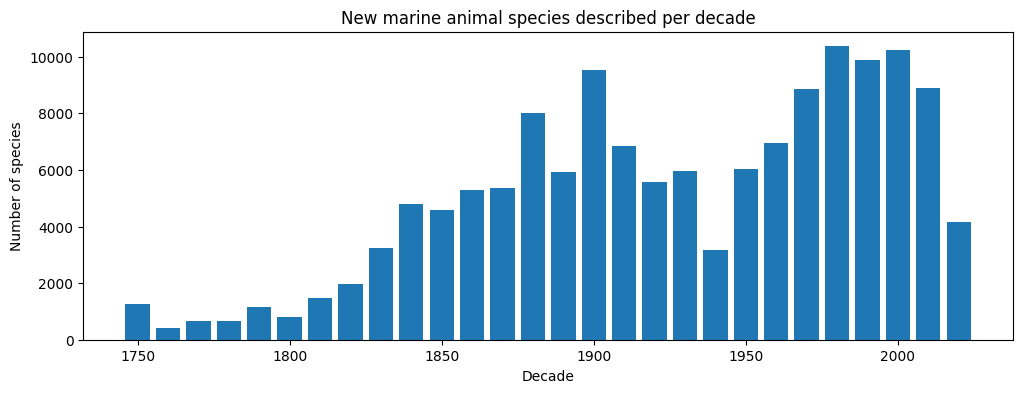

In [8]:
# 5- bar chart
plt.figure(figsize=(12, 4))
plt.bar(per_decade.index, per_decade.values, width=8)
plt.title("New marine animal species described per decade")
plt.xlabel("Decade")
plt.ylabel("Number of species")
plt.show()

**What did you learn? (2–3 lines with numbers)**

Answer:
* We are still discovering ocean animals: about 9,000–10,000 new species were described in each decade from 1980 to 2010 (10,364 in the 1980s, 8,896 in the 2010s).
* The curve has not flattened, so the ocean still hides many species we have not found yet.
* The 2020s look lower (4,166) only because the decade is not finished. 190 species had no year in the text and were left out.

# Task 1.2 — Rare and deep treasures

* What % of species were recorded only **once** (`records == 1`)?
* In `corals` (deep-sea corals and sponges): the 10 deepest species (`max_depth_m`)
* How many species are deeper than 1,000 m, and how many have a photo (`ImageURL` not empty)?

In [9]:
#Task 1.2 — Rare and deep treasures

#1- species recorded only once
seen_once = species[species["records"] == 1]

print("Species seen only once:", len(seen_once))
print("Percent:", round(len(seen_once) / len(species) * 100, 1), "%")

Species seen only once: 26936
Percent: 18.9 %


In [10]:
#2- the 10 deepest species
deepest = corals.sort_values("max_depth_m", ascending=False).head(10)

print("\n10 deepest species:")
deepest[["ScientificName", "VernacularNameCategory", "Ocean", "max_depth_m"]]


10 deepest species:


,ScientificName,VernacularNameCategory,Ocean,max_depth_m
0,Umbellula,sea pen,North Atlantic,6369.0
1,Umbellula magniflora,sea pen,South Atlantic,5895.0
2,Cladorhizidae,demosponge,North Pacific,5894.0
3,Porifera,sponge (unspecified),South Pacific,5855.0
4,Caulophacus,glass sponge,South Pacific,5853.0
5,Asbestopluma,demosponge,South Pacific,5852.0
6,Conopora verrucosa,lace coral,South Atlantic,5845.0
7,Abyssocladia marianensis,demosponge,North Pacific,5816.0
8,Abyssopathes lyra,black coral,South Pacific,5772.0
9,Hyalostylus,glass sponge,South Pacific,5771.0


In [11]:
#3- deeper than 1,000 m and how many have a photo
deep = corals[corals["max_depth_m"] > 1000]
with_photo = corals[corals["ImageURL"].notna()]
deep_with_photo = deep[deep["ImageURL"].notna()]

print("All deep-sea species:", len(corals))
print("Deeper than 1,000 m:", len(deep))
print("Have a photo:", len(with_photo), "(", round(len(with_photo) / len(corals) * 100, 1), "% )")
print("Deeper than 1,000 m AND have a photo:", len(deep_with_photo))

All deep-sea species: 4384
Deeper than 1,000 m: 1446
Have a photo: 1522 ( 34.7 % )
Deeper than 1,000 m AND have a photo: 748


**What did you learn? (2–3 lines with numbers)**

Answer:
* Many species are barely known: 26,936 species (18.9%) were recorded only once in history.
* Life reaches extreme depths: the deepest is a sea pen at 6,369 m, and 1,446 deep-sea coral / sponge species live below 1,000 m (no sunlight).
* Only 1,522 of 4,384 (34.7%) have a photo in the NOAA database, so about 2 out of 3 deep-sea species have no photo at all.

# Task 2.1 — More sampling = more species?

Each row of `grid` is a 5° × 5° ocean cell.

* Scatter plot: log(`obis_records`) vs log(`obis_species`)
* Correlation between them

Hint:
```
np.log1p(grid["obis_records"])
```

In [12]:
#Task 2.1 — More sampling = more species?

#1- log because the numbers are very spread out (1 -> 25 million)
log_records = np.log1p(grid["obis_records"])
log_species = np.log1p(grid["obis_species"])

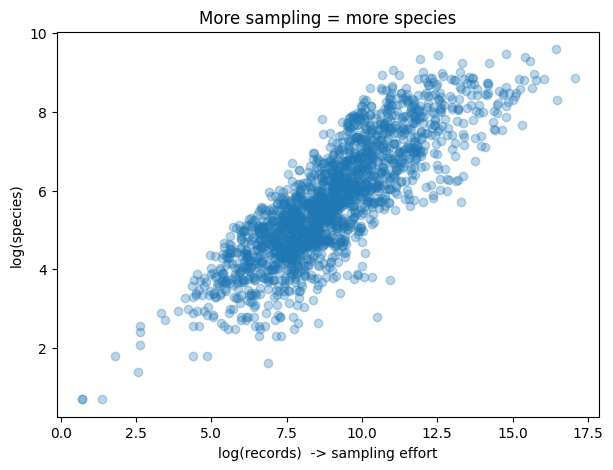

In [13]:
#2- scatter plot: each dot is one ocean cell
plt.figure(figsize=(7, 5))
plt.scatter(log_records, log_species, alpha=0.3)
plt.title("More sampling = more species")
plt.xlabel("log(records)  -> sampling effort")
plt.ylabel("log(species)")
plt.show()

In [14]:
#3- correlation (log vs raw)
print("Correlation (log):", round(log_records.corr(log_species), 2))
print("Correlation (raw):", round(grid["obis_records"].corr(grid["obis_species"]), 2))

Correlation (log): 0.83
Correlation (raw): 0.43


**What did you learn? (2–3 lines with numbers)**

Answer:
* More sampling = more species: across 1,881 ocean cells, the correlation between log(records) and log(species) is 0.83 (very strong).
* Without the log it is only 0.43, because records range from 1 to 25 million; the log makes the real relationship visible.
* So a low species count can mean "not searched enough", not "not rich". This is sampling bias, and it is why Model 1 must estimate the expected species, not just count the recorded ones.

# Task 2.2 — Where does life live?

* Species vs sea temperature (`sst_mean`) → scatter or groups (cold / mild / warm)
* Species vs depth (`depth_mean`)
* Map: `plt.scatter(grid["cell_lon"], grid["cell_lat"], c=np.log1p(grid["obis_species"]))`

Question: are the richest cells in warm or cold seas?

In [15]:
#Task 2.2 — Where does life live?

#missing temperature
print("Cells with no temperature:", grid["sst_mean"].isna().sum())

#1- group the cells by sea temperature
grid["temp_group"] = pd.cut(grid["sst_mean"], bins=[-5, 10, 20, 40],
                            labels=["cold (<10)", "mild (10-20)", "warm (>20)"])

#median species and median records in each group
grid.groupby("temp_group", observed=True)[["obis_species", "obis_records"]].median()

Cells with no temperature: 31


,obis_species,obis_records
temp_group,,
cold (<10),169.0,5636.0
mild (10-20),297.0,7260.0
warm (>20),503.0,9545.0


In [16]:
#2- group the cells by depth
grid["depth_group"] = pd.cut(grid["depth_mean"], bins=[-1, 200, 1000, 4000, 20000],
                             labels=["shallow (<200)", "200-1000", "1000-4000", "deep (>4000)"])

grid.groupby("depth_group", observed=True)[["obis_species", "obis_records"]].median()

,obis_species,obis_records
depth_group,,
shallow (<200),366.5,6060.0
200-1000,424.0,10339.0
1000-4000,456.0,13386.0
deep (>4000),162.0,4043.0


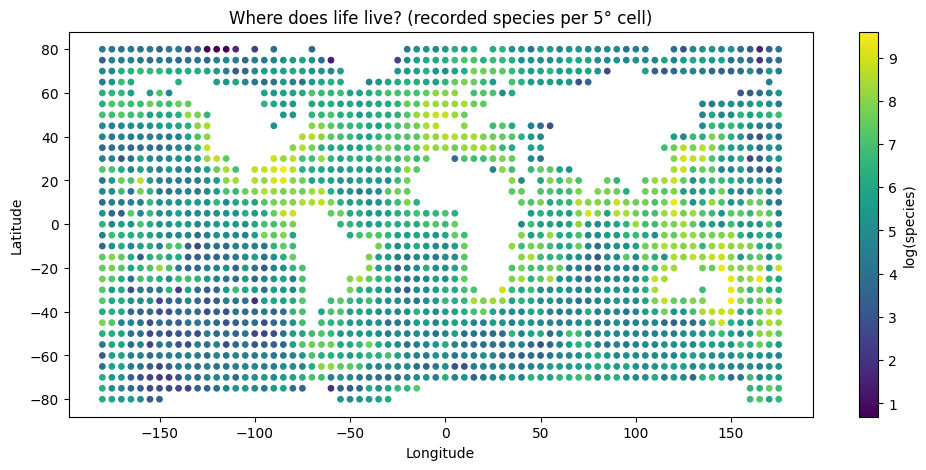

In [17]:
#3- world map: each dot is one ocean cell, color = number of species (log)
plt.figure(figsize=(12, 5))
plt.scatter(grid["cell_lon"], grid["cell_lat"], c=np.log1p(grid["obis_species"]),
            cmap="viridis", s=15)
plt.colorbar(label="log(species)")
plt.title("Where does life live? (recorded species per 5° cell)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

**What did you learn? (2–3 lines with numbers)**

Answer:
* Life lives in warm seas: warm cells (>20 °C) have a median of 503 species vs 169 in cold cells (<10 °C), about 3× more, while sampling is only 1.7× higher (9,545 vs 5,636 records). 20 °C ≈ the minimum temperature for coral reefs.
* The deepest cells (>4,000 m) show the fewest species (162) but also the least sampling (4,043 records), so we cannot tell if they are poor or just unexplored (sampling bias).
* The map shows the richest cells along warm coasts (Caribbean, Southeast Asia, eastern Australia) and near well-studied regions (Europe, Japan), while the open South Pacific and the poles are poorest, which mixes real richness with sampling bias.
* 31 cells have no sea temperature.

---
# 🔥 PART 2 — DANGER (Member 2)

# Task 3.1 — Data quality check

* How many rows have a bleaching % (`Percent_Bleaching` not missing)?
* How many unique `Sample_ID`? (each sample is repeated once per seabed type)
* How many rows have `ClimSST == 262.15` (fake −11 °C)?
* Missing values per column (bar chart of the top 10)

In [18]:
#TO-DO

**What did you learn? (2–3 lines with numbers)**

Answer:

# Task 3.2 — Create the target and check balance

Keep one row per sample, then create:
```
0 = none    -> Percent_Bleaching == 0
1 = mild    -> between 0 and 20
2 = severe  -> 20 or more
```
Plot the class balance. Is it balanced?

Hint:
```
df = bleaching[bleaching["Percent_Bleaching"].notna()].drop_duplicates("Sample_ID")
```

In [19]:
#TO-DO

**What did you learn? (2–3 lines with numbers)**

Answer:

# Task 3.3 — Heat stress vs bleaching

`TSA_DHW` = heat stress (degree heating weeks).

* Group it: 0 / 0–2 / 2–4 / 4–8 / 8+
* Share of severe bleaching in each group → bar chart
* Correlation heatmap: heat columns (`TSA_DHW`, `SSTA_DHW`, `TSA`, `SSTA`, `Temperature_Maximum`, ...) with `Percent_Bleaching`

Hint:
```
pd.cut(df["TSA_DHW"], bins=[-0.1, 0, 2, 4, 8, 100], labels=["0", "0-2", "2-4", "4-8", "8+"])
```

In [20]:
#TO-DO

**What did you learn? (2–3 lines with numbers)**

Answer:

# Task 3.4 — Is the ocean warming?

Line chart of `sea_temperature_anomaly_annual` for `entity == "World"` (1850 → today).

In [21]:
#TO-DO

**What did you learn? (2–3 lines with numbers)**

Answer:

# Task 4.1 — Does losing coral mean losing fish?

* Merge `surveys` with `sites` on `site_code` (to get `lat_zone`)
* Box plot: fish species per survey by `lat_zone`
* Group `hard_coral_pct`: 0 / 0–10 / 10–30 / 30–50 / 50+ → average `fish_species` per group (bar chart)

In [22]:
#TO-DO

**What did you learn? (2–3 lines with numbers)**

Answer:

---
# ⚠️ PART 3 — AT RISK (Member 3)

# Task 5.1 — Heat stress today

* Take the **last day** of each station in `heat`
* How many stations have `dhw >= 4` (bleaching alert)?
* Top 10 hottest stations today
* Map: merge with `stations` (lat / lon) and color by `dhw`

Hint:
```
today = heat.groupby("station").tail(1)
```

In [23]:
#TO-DO

**What did you learn? (2–3 lines with numbers)**

Answer:

# Task 5.2 — Heat over time in Saudi waters

Line chart of `dhw` over the last 2 years for:
```
Jazan, Saudi Arabia
Al Madinah and Makkah
Tabuk, Saudi Arabia
```
Add a horizontal line at DHW = 4 and DHW = 8.

Hint:
```
heat["date"] = pd.to_datetime(heat[["year", "month", "day"]])
```

In [24]:
#TO-DO

**What did you learn? (2–3 lines with numbers)**

Answer:

# Task 6.1 — The Red Sea twist

Under strong heat (`TSA_DHW >= 4`), compare the share of **severe** bleaching:
```
Red Sea      -> Ecoregion_Name contains "Red Sea" or "Gulf of Aden"
Rest of world
```
Show the number of surveys for each group too. What does it mean for Saudi reefs?

Hint:
```
df["Ecoregion_Name"].str.contains("Red Sea|Gulf of Aden", na=False)
```

In [25]:
#TO-DO

**What did you learn? (2–3 lines with numbers)**

Answer:

---
# 🤿 PART 4 — DIVE & ACT (Member 4)

# Task 7.1 — Dive sites

* Share of sites per country (top 10) → sampling bias?
* Distribution of `visibility` and `fish_species` per survey
* Top 10 sites by average fish species (merge `surveys` with `sites`)

In [26]:
#TO-DO

**What did you learn? (2–3 lines with numbers)**

Answer:

# Task 7.2 — Rare creatures near dive sites

* Count of threatened species by `category` (CR = critically endangered, EN = endangered, VU = vulnerable)
* The 10 most common threatened species near our dive sites
* Which site has the most CR species?

In [27]:
#TO-DO

**What did you learn? (2–3 lines with numbers)**

Answer:

---
# Task 8 — Summary (everyone)

Write the **5 most important numbers** for our story (one per tab), for example:
```
1 Why care?      -> ...
2 Discover       -> ...
3 Danger         -> ...
4 At Risk        -> ...
5 Dive & Act     -> ...
```

Answer: